# 04. Трансформер: M3 DistilBERT і M4 гібрид

## 0. Середовище

In [ ]:
import json
import math
import os
import sys
import time
from pathlib import Path

try:
    from google.colab import drive

    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/fabula")
except ImportError:
    BASE = Path("..").resolve()

sys.path.append(str(BASE))
SMOKE = os.environ.get("FABULA_SMOKE") == "1"
print("BASE:", BASE, "| SMOKE:", SMOKE)

Mounted at /content/drive
BASE: /content/drive/MyDrive/fabula | SMOKE: False


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer

from fabula_eval import LEVELS, annotator_level_ids, bootstrap_ci, class_f1, evaluate, macro_f1, plot_confusion
from fabula_transformer import (
    FeatureScaler, HybridClassifier, balanced_class_weights, encode_all, export_state,
    predict_from_pooled, predict_logits, set_seed, train_classifier,
)

DATA_DIR = BASE / "data" / "processed"
RESULTS_DIR = BASE / "results" / ("04_smoke" if SMOKE else "04")
MODELS_DIR = BASE / "models"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (RESULTS_DIR, MODELS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 64
BATCH_SIZE = 32
EPOCHS = 1 if SMOKE else 4
LEARNING_RATE = 3e-5
SEEDS = [42] if SMOKE else [42, 43, 44]
PERMUTATION_REPEATS = 2 if SMOKE else 5
print("Пристрій:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Пристрій: cuda Tesla T4


## 1. Дані

In [ ]:
def load_split(split):
    features = pd.read_csv(DATA_DIR / f"features_{split}.csv")
    sentences = pd.read_csv(DATA_DIR / f"cefr_sp_{split}.csv")
    assert (features["text"] == sentences["text"]).all()
    features["level_a"] = annotator_level_ids(sentences["label_a"])
    features["level_b"] = annotator_level_ids(sentences["label_b"])
    return features


splits = {name: load_split(name) for name in ["train", "validation", "test"]}
if SMOKE:
    splits = {name: frame.groupby("level_id").head(12 if name == "train" else 4).reset_index(drop=True)
              for name, frame in splits.items()}

ALL_FEATURES = [c for c in splits["train"].columns
                if c not in {"text", "level", "level_id", "source", "level_a", "level_b"}]
FEATURE_GROUPS = json.load(open(BASE / "results" / "02_feature_groups.json", encoding="utf-8"))
RF_FEATURES = json.load(open(BASE / "results" / "03_selected_features.json", encoding="utf-8"))["features"]
labels = {name: frame["level_id"].to_numpy() for name, frame in splits.items()}
print({name: len(frame) for name, frame in splits.items()}, "| ознак:", len(ALL_FEATURES), "| RF:", len(RF_FEATURES))

{'train': 7002, 'validation': 1500, 'test': 1501} | ознак: 33 | RF: 13


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
lengths = [len(ids) for ids in tokenizer(splits["train"]["text"].tolist())["input_ids"]]
print(f"Довжина в токенах: медіана {np.median(lengths):.0f}, максимум {max(lengths)}, обрізано {np.mean(np.array(lengths) > MAX_LENGTH):.2%}")

tokens = {
    name: tokenizer(frame["text"].tolist(), padding="max_length", truncation=True,
                    max_length=MAX_LENGTH, return_tensors="pt")
    for name, frame in splits.items()
}

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Довжина в токенах: медіана 17, максимум 48, обрізано 0.00%


## 2. Запуск експериментів

In [ ]:
def make_inputs(split, feature_names, scaler):
    features = None
    if feature_names:
        features = torch.tensor(scaler.transform(splits[split][feature_names].to_numpy(dtype=np.float64)))
    return {"input_ids": tokens[split]["input_ids"], "attention_mask": tokens[split]["attention_mask"],
            "features": features}


def score(split, predictions):
    frame = splits[split]
    return evaluate(frame["level_id"], predictions, frame["level_a"], frame["level_b"])


def run(name, feature_names, class_weighted, seed, keep_model=False):
    run_id = f"{name}_seed{seed}"
    metrics_path = RESULTS_DIR / f"{run_id}.json"
    if metrics_path.exists() and not keep_model:
        print(f"{run_id}: вже є, пропускаю")
        return json.load(open(metrics_path, encoding="utf-8")), None, None

    set_seed(seed)
    scaler = FeatureScaler.fit(splits["train"][feature_names].to_numpy(dtype=np.float64)) if feature_names else None
    inputs = {split: make_inputs(split, feature_names, scaler) for split in splits}
    model = HybridClassifier(MODEL_NAME, n_features=len(feature_names))
    started = time.perf_counter()
    model, history = train_classifier(
        model, inputs["train"], labels["train"], inputs["validation"],
        score_fn=lambda predictions: macro_f1(labels["validation"], predictions),
        device=DEVICE, epochs=EPOCHS, learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, seed=seed,
        class_weights=balanced_class_weights(labels["train"]) if class_weighted else None,
    )
    result = {"name": name, "seed": seed, "features": feature_names, "class_weighted": class_weighted,
              "minutes": round((time.perf_counter() - started) / 60, 2), "history": history}
    for split in ["validation", "test"]:
        logits = predict_logits(model, inputs[split]["input_ids"], inputs[split]["attention_mask"],
                                inputs[split]["features"], DEVICE)
        predictions = logits.argmax(axis=1)
        result[split] = score(split, predictions)
        pd.DataFrame({"level_id": labels[split], "prediction": predictions,
                      **{f"logit_{level}": logits[:, i] for i, level in enumerate(LEVELS)}}
                     ).to_csv(RESULTS_DIR / f"{run_id}_{split}.csv", index=False)
    json.dump(result, open(metrics_path, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    print(f"{run_id}: val macro-F1 {result['validation']['macro_f1']:.3f}, "
          f"test {result['test']['macro_f1']:.3f}, {result['minutes']} хв")
    return result, model, scaler


def summarize(names):
    rows = []
    for path in sorted(RESULTS_DIR.glob("*_seed*.json")):
        result = json.load(open(path, encoding="utf-8"))
        if result["name"] in names:
            rows.append({"name": result["name"], "seed": result["seed"],
                         **{f"val_{k}": v for k, v in result["validation"].items()},
                         **{f"test_{k}": v for k, v in result["test"].items()}})
    return pd.DataFrame(rows)


saved_states = {}


def run_and_keep_best(name, feature_names, class_weighted):
    best = None
    for seed in SEEDS:
        result, model, scaler = run(name, feature_names, class_weighted, seed, keep_model=True)
        if best is None or result["validation"]["macro_f1"] > best["score"]:
            best = {"score": result["validation"]["macro_f1"], "seed": seed, "state": export_state(model),
                    "scaler": scaler.to_dict() if scaler else None, "features": feature_names,
                    "class_weighted": class_weighted}
        del model
        torch.cuda.empty_cache()
    saved_states[name] = best
    return best

## 3. M3: DistilBERT без ознак, з вагами класів і без

In [ ]:
m3_plain = run_and_keep_best("M3", [], class_weighted=False)
m3_weighted = run_and_keep_best("M3_weighted", [], class_weighted=True)
m3_runs = summarize({"M3", "M3_weighted"})
m3_means = m3_runs.groupby("name")[["val_macro_f1", "val_f1_A1", "test_macro_f1"]].agg(["mean", "std"]).round(3)
CLASS_WEIGHTED = bool(m3_runs.groupby("name")["val_macro_f1"].mean().idxmax() == "M3_weighted")
M3_NAME = "M3_weighted" if CLASS_WEIGHTED else "M3"
print("Ваги класів для трансформера:", CLASS_WEIGHTED)
m3_means

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/fabula/fabula_transformer.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


M3_seed42: val macro-F1 0.656, test 0.616, 1.16 хв


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M3_weighted_seed44: val macro-F1 0.635, test 0.616, 1.09 хв
Ваги класів для трансформера: False


val_macro_f1        val_f1_A1        test_macro_f1       
                    mean    std      mean    std          mean    std
name                                                                 
M3                 0.653  0.003     0.535  0.017         0.619  0.003
M3_weighted        0.625  0.010     0.493  0.024         0.606  0.009

## 4. M4: гібрид з 13 ознаками Random Forest і з усіма 33

In [ ]:
for seed in SEEDS:
    run("M4_rf13", RF_FEATURES, CLASS_WEIGHTED, seed)

permutation_rows = []
for seed in SEEDS:
    result, model, scaler = run("M4_all33", ALL_FEATURES, CLASS_WEIGHTED, seed, keep_model=True)
    val_inputs = make_inputs("validation", ALL_FEATURES, scaler)
    pooled = encode_all(model, val_inputs["input_ids"], val_inputs["attention_mask"], DEVICE)
    features = val_inputs["features"]
    base_score = macro_f1(labels["validation"], predict_from_pooled(model, pooled, features, DEVICE))
    rng = np.random.default_rng(seed)

    def permuted_score(columns):
        scores = []
        for _ in range(PERMUTATION_REPEATS):
            shuffled = features.clone()
            order = torch.tensor(rng.permutation(len(shuffled)))
            shuffled[:, columns] = shuffled[order][:, columns]
            scores.append(macro_f1(labels["validation"], predict_from_pooled(model, pooled, shuffled, DEVICE)))
        return float(np.mean(scores))

    for index, feature in enumerate(ALL_FEATURES):
        permutation_rows.append({"seed": seed, "kind": "feature", "name": feature,
                                 "importance": base_score - permuted_score([index])})
    for group, names in FEATURE_GROUPS.items():
        columns = [ALL_FEATURES.index(name) for name in names]
        permutation_rows.append({"seed": seed, "kind": "group", "name": group,
                                 "importance": base_score - permuted_score(columns)})
    del model
    torch.cuda.empty_cache()

permutation = pd.DataFrame(permutation_rows)
permutation.to_csv(RESULTS_DIR / "permutation_importance.csv", index=False)
summarize({"M4_rf13", "M4_all33"}).groupby("name")[["val_macro_f1", "test_macro_f1"]].agg(["mean", "std"]).round(3)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/fabula/fabula_transformer.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


M4_rf13_seed42: val macro-F1 0.654, test 0.628, 1.1 хв


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/fabula/fabula_transformer.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


M4_rf13_seed43: val macro-F1 0.665, test 0.624, 1.1 хв


... (9 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/fabula/fabula_transformer.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


M4_all33_seed44: val macro-F1 0.649, test 0.609, 1.1 хв


val_macro_f1        test_macro_f1       
                 mean    std          mean    std
name                                             
M4_all33        0.640  0.013         0.619  0.009
M4_rf13         0.657  0.007         0.623  0.005

## 5. Відбір ознак для трансформера

In [ ]:
feature_importance = permutation[permutation["kind"] == "feature"].pivot(index="name", columns="seed", values="importance")
feature_importance["mean"] = feature_importance[SEEDS].mean(axis=1)
feature_importance["positive_seeds"] = (feature_importance[SEEDS] > 0).sum(axis=1)
required = math.ceil(2 * len(SEEDS) / 3)
feature_importance["selected"] = (feature_importance["mean"] > 0) & (feature_importance["positive_seeds"] >= required)
TRANSFORMER_FEATURES = [name for name in ALL_FEATURES if feature_importance.loc[name, "selected"]]
if not TRANSFORMER_FEATURES:
    TRANSFORMER_FEATURES = [feature_importance["mean"].idxmax()]

group_of = {name: group for group, names in FEATURE_GROUPS.items() for name in names}
feature_importance["group"] = feature_importance.index.map(group_of)
feature_importance["in_rf13"] = feature_importance.index.isin(RF_FEATURES)
feature_importance.to_csv(RESULTS_DIR / "feature_importance_m4.csv")
json.dump({"features": TRANSFORMER_FEATURES, "rule": f"mean > 0 and positive in >= {required} of {len(SEEDS)} seeds"},
          open(RESULTS_DIR / "selected_features_m4.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(f"Відібрано {len(TRANSFORMER_FEATURES)} ознак:", TRANSFORMER_FEATURES)
feature_importance.sort_values("mean", ascending=False)[["group", "mean", "positive_seeds", "selected", "in_rf13"]].round(4)

Відібрано 23 ознак: ['chars_per_word', 'n_syllables', 'share_a1', 'share_a2', 'share_b1', 'share_c', 'share_oov', 'max_word_level', 'mean_word_level', 'mean_zipf', 'min_zipf', 'type_token_ratio', 'lexical_density', 'tree_depth', 'n_finite_verbs', 'has_past', 'has_present', 'has_progressive', 'n_modals', 'n_contractions', 'is_question', 'has_vocative', 'share_personal_pronouns']


seed,group,mean,positive_seeds,selected,in_rf13
name,,,,,
chars_per_word,length,0.0049,2,True,True
tree_depth,grammar,0.0039,3,True,True
share_a1,lexical,0.0039,3,True,True
min_zipf,lexical,0.0036,2,True,True
lexical_density,lexical,0.0036,3,True,True
is_question,dialogue,0.0034,2,True,False
share_personal_pronouns,dialogue,0.0031,2,True,False
has_past,grammar,0.0026,2,True,False
max_word_level,lexical,0.0026,2,True,True


In [ ]:
permutation[permutation["kind"] == "group"].pivot(index="name", columns="seed", values="importance").assign(
    mean=lambda frame: frame.mean(axis=1)).sort_values("mean", ascending=False).round(4)

seed,42,43,44,mean
name,,,,
length,0.0004,0.0059,0.0079,0.0047
lexical,0.0049,0.0035,0.0034,0.0040
grammar,0.0005,0.0054,0.0043,0.0034
dialogue,-0.0002,-0.0001,0.0096,0.0031


## 6. M4-final: гібрид з ознаками, відібраними для трансформера

In [ ]:
m4_final = run_and_keep_best("M4_final", TRANSFORMER_FEATURES, CLASS_WEIGHTED)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/fabula/fabula_transformer.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


M4_final_seed42: val macro-F1 0.634, test 0.627, 1.1 хв


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/fabula/fabula_transformer.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


M4_final_seed43: val macro-F1 0.652, test 0.620, 1.1 хв


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/fabula/fabula_transformer.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


M4_final_seed44: val macro-F1 0.650, test 0.632, 1.1 хв


## 7. Порівняння на test

In [ ]:
names = ["M3", "M3_weighted", "M4_rf13", "M4_all33", "M4_final"]
runs = summarize(set(names))
runs.to_csv(RESULTS_DIR / "runs.csv", index=False)
columns = ["macro_f1", "macro_f1_lenient", "accuracy", "adjacent_accuracy", "qwk", "f1_A1", "f1_C"]
summary = runs.groupby("name")[[f"test_{c}" for c in columns]].agg(["mean", "std"]).reindex(names).round(3)
summary.to_csv(RESULTS_DIR / "summary_test.csv")
summary

test_macro_f1        test_macro_f1_lenient        test_accuracy  \
                     mean    std                  mean    std          mean   
name                                                                          
M3                  0.619  0.003                 0.746  0.026         0.665   
M3_weighted         0.606  0.009                 0.769  0.016         0.641   
M4_rf13             0.623  0.005                 0.749  0.007         0.676   
M4_all33            0.619  0.009                 0.751  0.004         0.672   
M4_final            0.626  0.006                 0.745  0.009         0.676   

                   test_adjacent_accuracy        test_qwk        test_f1_A1  \
               std                   mean    std     mean    std       mean   
name                                                                          
M3           0.003                  0.997  0.001    0.815  0.003      0.426   
M3_weighted  0.015                  0.994  0.002    0.816  0.006      0.430   
M4_rf13      0.010                  0.996  0.000    0.819  0.003      0.406   
M4_all33     0.005                  0.996  0.000    0.817  0.003      0.400   
M4_final     0.005                  0.996  0.000    0.820  0.004      0.411   

                   test_f1_C         
               std      mean    std  
name                                 
M3           0.016     0.718  0.010  
M3_weighted  0.042     0.723  0.003  
M4_rf13      0.019     0.719  0.009  
M4_all33     0.016     0.725  0.003  
M4_final     0.010     0.731  0.011

In [ ]:
ci_rows = {}
for name in [M3_NAME, "M4_final"]:
    seed = saved_states[name]["seed"]
    predictions = pd.read_csv(RESULTS_DIR / f"{name}_seed{seed}_test.csv")
    y_true, y_pred = predictions["level_id"].to_numpy(), predictions["prediction"].to_numpy()
    low, high = bootstrap_ci(y_true, y_pred)
    a1_low, a1_high = bootstrap_ci(y_true, y_pred, metric=class_f1(0))
    ci_rows[f"{name} (seed {seed})"] = score("test", y_pred) | {
        "macro_f1_ci": f"[{low:.3f}; {high:.3f}]", "f1_A1_ci": f"[{a1_low:.3f}; {a1_high:.3f}]"}
best_seed_results = pd.DataFrame(ci_rows).T
best_seed_results.to_csv(RESULTS_DIR / "best_seed_test.csv")
best_seed_results[["macro_f1", "macro_f1_ci", "macro_f1_lenient", "adjacent_accuracy", "qwk", "f1_A1", "f1_A1_ci"]]

,macro_f1,macro_f1_ci,macro_f1_lenient,adjacent_accuracy,qwk,f1_A1,f1_A1_ci
M3 (seed 42),0.616169,[0.553; 0.667],0.73648,0.996669,0.814901,0.416667,[0.118; 0.645]
M4_final (seed 43),0.620051,[0.558; 0.671],0.735288,0.996003,0.816038,0.4,[0.111; 0.632]


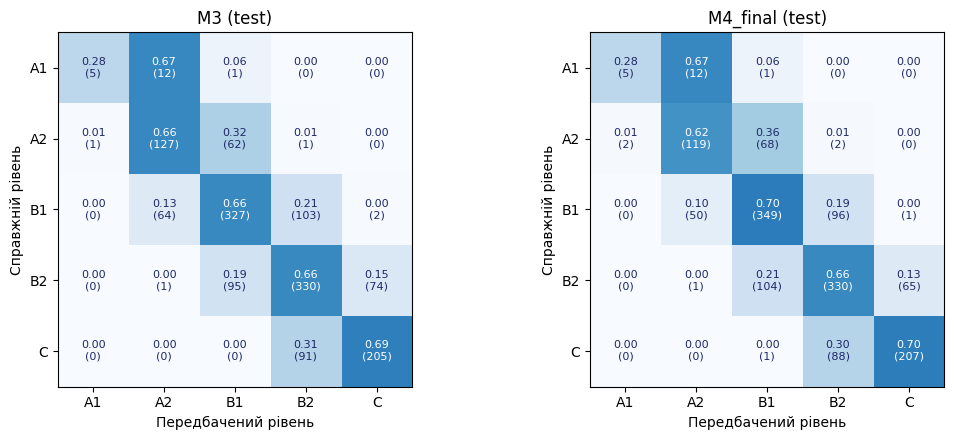

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, [M3_NAME, "M4_final"]):
    seed = saved_states[name]["seed"]
    predictions = pd.read_csv(RESULTS_DIR / f"{name}_seed{seed}_test.csv")
    plot_confusion(predictions["level_id"], predictions["prediction"], f"{name} (test)", ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_confusion_test.png", dpi=150)
plt.show()

## 8. Ефект джерела

In [ ]:
source_rows = {}
for name in [M3_NAME, "M4_final"]:
    seed = saved_states[name]["seed"]
    predictions = pd.read_csv(RESULTS_DIR / f"{name}_seed{seed}_test.csv")["prediction"].to_numpy()
    for source in sorted(splits["test"]["source"].unique()):
        mask = (splits["test"]["source"] == source).to_numpy()
        frame = splits["test"][mask]
        source_rows[f"{name} | {source}"] = evaluate(frame["level_id"], predictions[mask],
                                                    frame["level_a"], frame["level_b"])
pd.DataFrame(source_rows).T[["macro_f1", "macro_f1_lenient", "accuracy", "f1_A1"]].round(3)

,macro_f1,macro_f1_lenient,accuracy,f1_A1
M3 | SCoRE,0.398,0.551,0.632,0.000
M3 | Wiki-Auto,0.670,0.766,0.673,0.769
M4_final | SCoRE,0.467,0.659,0.658,0.000
M4_final | Wiki-Auto,0.662,0.769,0.678,0.714


## 9. Збереження моделей

In [ ]:
for name, file_name in [(M3_NAME, "m3_distilbert.pt"), ("M4_final", "m4_hybrid.pt")]:
    best = saved_states[name]
    torch.save({"model_name": MODEL_NAME, "max_length": MAX_LENGTH, "levels": LEVELS,
                "features": best["features"], "scaler": best["scaler"], "seed": best["seed"],
                "class_weighted": best["class_weighted"], "state_dict": best["state"]},
               MODELS_DIR / ("smoke_" + file_name if SMOKE else file_name))
{path.name: f"{path.stat().st_size / 1e6:.0f} MB" for path in MODELS_DIR.glob("*.pt")}

{'m3_distilbert.pt': '133 MB', 'm4_hybrid.pt': '133 MB'}

## 10. Зсув порогу для A1 (локально, на збережених logits)

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from fabula_eval import LEVELS, annotator_level_ids, evaluate, macro_f1

RUNS_DIR = ROOT / "results" / "04"
BIAS_GRID = np.round(np.arange(0.0, 4.01, 0.25), 2)
logit_columns = [f"logit_{level}" for level in LEVELS]


def annotator_levels(split):
    sentences = pd.read_csv(ROOT / "data" / "processed" / f"cefr_sp_{split}.csv")
    return annotator_level_ids(sentences["label_a"]), annotator_level_ids(sentences["label_b"])


annotators = {split: annotator_levels(split) for split in ["validation", "test"]}


def shifted_predictions(frame, bias):
    logits = frame[logit_columns].to_numpy().copy()
    logits[:, 0] += bias
    return logits.argmax(axis=1)


rows = []
for metrics_path in sorted(RUNS_DIR.glob("*_seed*.json")):
    run = json.load(open(metrics_path, encoding="utf-8"))
    run_id = metrics_path.stem
    validation = pd.read_csv(RUNS_DIR / f"{run_id}_validation.csv")
    test = pd.read_csv(RUNS_DIR / f"{run_id}_test.csv")
    scores = [macro_f1(validation["level_id"], shifted_predictions(validation, bias)) for bias in BIAS_GRID]
    best_bias = float(BIAS_GRID[int(np.argmax(scores))])
    for bias, label in [(0.0, "без зсуву"), (best_bias, "зі зсувом")]:
        result = evaluate(test["level_id"], shifted_predictions(test, bias), *annotators["test"])
        rows.append({"name": run["name"], "seed": run["seed"], "варіант": label, "bias": bias, **result})

shift = pd.DataFrame(rows)
shift.to_csv(RUNS_DIR / "a1_bias_shift.csv", index=False)
shift.groupby(["name", "варіант"])[["bias", "macro_f1", "macro_f1_lenient", "accuracy", "f1_A1", "f1_A2"]].mean().round(3)

bias  macro_f1  macro_f1_lenient  accuracy  f1_A1  \
name        варіант                                                         
M3          без зсуву  0.000     0.619             0.746     0.665  0.426   
            зі зсувом  0.667     0.616             0.748     0.665  0.415   
M3_weighted без зсуву  0.000     0.606             0.769     0.641  0.430   
            зі зсувом  0.250     0.607             0.769     0.641  0.436   
M4_all33    без зсуву  0.000     0.619             0.751     0.672  0.400   
            зі зсувом  0.667     0.619             0.758     0.672  0.399   
M4_final    без зсуву  0.000     0.626             0.745     0.676  0.411   
            зі зсувом  0.583     0.628             0.765     0.676  0.422   
M4_rf13     без зсуву  0.000     0.623             0.749     0.676  0.406   
            зі зсувом  0.583     0.621             0.759     0.675  0.401   

                       f1_A2  
name        варіант           
M3          без зсуву  0.633  
            зі зсувом  0.630  
M3_weighted без зсуву  0.641  
            зі зсувом  0.642  
M4_all33    без зсуву  0.637  
            зі зсувом  0.635  
M4_final    без зсуву  0.654  
            зі зсувом  0.650  
M4_rf13     без зсуву  0.643  
            зі зсувом  0.639

## 11. Додаткові моделі для етапу 5: M4-13 і M4-33 (Colab)

In [ ]:
EXTRA_MODELS = [
    ("M4_rf13", RF_FEATURES, 43, "m4_rf13.pt"),
    ("M4_all33", ALL_FEATURES, 44, "m4_all33.pt"),
]

for name, feature_names, seed, file_name in EXTRA_MODELS:
    set_seed(seed)
    scaler = FeatureScaler.fit(splits["train"][feature_names].to_numpy(dtype=np.float64))
    inputs = {split: make_inputs(split, feature_names, scaler) for split in splits}
    model = HybridClassifier(MODEL_NAME, n_features=len(feature_names))
    model, history = train_classifier(
        model, inputs["train"], labels["train"], inputs["validation"],
        score_fn=lambda predictions: macro_f1(labels["validation"], predictions),
        device=DEVICE, epochs=EPOCHS, learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, seed=seed,
        class_weights=None,
    )
    for split in ["validation", "test"]:
        logits = predict_logits(model, inputs[split]["input_ids"], inputs[split]["attention_mask"],
                                inputs[split]["features"], DEVICE)
        print(f"{name} seed {seed} | {split} macro-F1 {macro_f1(labels[split], logits.argmax(axis=1)):.3f}")
    torch.save({"model_name": MODEL_NAME, "max_length": MAX_LENGTH, "levels": LEVELS,
                "features": feature_names, "scaler": scaler.to_dict(), "seed": seed,
                "class_weighted": False, "state_dict": export_state(model)},
               MODELS_DIR / file_name)
    del model
    torch.cuda.empty_cache()

{path.name: f"{path.stat().st_size / 1e6:.0f} MB" for path in MODELS_DIR.glob("*.pt")}

M4_rf13 seed 43 | validation macro-F1 0.665
M4_rf13 seed 43 | test macro-F1 0.624
M4_all33 seed 44 | validation macro-F1 0.649
M4_all33 seed 44 | test macro-F1 0.609


{'m3_distilbert.pt': '133 MB',
 'm4_hybrid.pt': '133 MB',
 'm4_rf13.pt': '133 MB',
 'm4_all33.pt': '133 MB'}

## 12. Висновки

| Модель (test, 3 seed) | macro-F1 | macro-F1 м'яка | ±1 рівень | QWK | F1 A1 |
| --- | --- | --- | --- | --- | --- |
| M2 Random Forest (етап 3) | 0.580 | 0.729 | 0.983 | 0.770 | 0.400 |
| M3 DistilBERT | 0.619 ± 0.003 | 0.746 | 0.997 | 0.815 | 0.426 |
| M3 з вагами класів | 0.606 ± 0.009 | 0.769 | 0.994 | 0.816 | 0.430 |
| M4-13 (ознаки Random Forest) | 0.623 ± 0.005 | 0.749 | 0.996 | 0.819 | 0.406 |
| M4-33 (усі ознаки) | 0.619 ± 0.009 | 0.751 | 0.996 | 0.817 | 0.400 |
| M4-final (23 ознаки) | 0.626 ± 0.006 | 0.745 | 0.996 | 0.820 | 0.411 |

- Трансформер кращий за Random Forest: +0.04 macro-F1, +0.05 QWK, помилки більше ніж на 1 рівень майже зникли (±1 = 99.7%).
- Гібрид кращий за M3 на 0.004–0.007, що менше за розкид між seed; ДІ M3 0.553–0.667, M4-final 0.558–0.671.
- За validation найкращий M4-13 (0.657), M3 0.653, M4-final 0.645, M4-33 0.640.
- Ваги класів трансформеру шкодять (0.653 → 0.625 на validation).
- Важливість ознак у гібриді ≤ 0.005 macro-F1 (у Random Forest до 0.115); групи важать порівну (0.003–0.005).
- Для трансформера відібрано 23 ознаки, серед них діалогові: is_question, share_personal_pronouns, n_contractions, has_vocative.
- Ефект джерела: на SCoRE гібрид кращий за M3 (0.467 проти 0.398; м'яка 0.659 проти 0.551), на Wiki-Auto однаковий.
- A1: 12 з 18 речень A1 передбачено як A2; усі A1 із SCoRE пропущено. Зсув порогу A1 (підібраний на validation) не змінює F1 A1 на test більше ніж на 0.01.
- Остаточний вибір моделі — на етапі 5, за якістю на діалогах.
- M4-13 (seed 43) і M4-33 (seed 44) перенавчено окремо для етапу 5; метрики збіглися з основним запуском до третього знака.